# Aula 1 — Visualização de dados espectrais
**Módulo `geocis_espectral.visualizacao`**

**Objetivos:** desenhar espectros individuais e médios, colorir por classe ou atributo,
localizar regiões e feições diagnósticas e comparar VIS–NIR–SWIR com MIR.

| Função | Para quê |
|---|---|
| `plot_spectra` | espectros individuais (cor única, por classe ou gradiente) |
| `plot_mean_std` | espectro médio ± DP (ou percentis), opcionalmente por grupo |
| `plot_vnir_mir` | as duas faixas lado a lado |
| `plot_heatmap` | toda a base como imagem (amostras × bandas) |
| `shade_regions`, `mark_features` | regiões VIS/NIR/SWIR e feições de absorção |
| `savefig` | salva em `outputs/figuras` a 300 dpi |

In [1]:
# --- Configuração (igual em todas as aulas) ---------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from geocis_espectral import dados, visualizacao as vz, processamento as pp
from geocis_espectral import exploratoria as ex, agrupamento as ag, modelagem as mo

vz.set_style()
pd.set_option("display.max_columns", 30)

# Base do GeoCiS: raw_nir_data_Saturin.csv + raw_mir_data_Saturin.csv.
# Na 1ª execução (ou se os CSV mudarem) a base pareada é preparada automaticamente (~30 s).
# Para demonstrações fora do GeoCiS, troque para FONTE = "synthetic".
FONTE = "paired"
ds = dados.load_dataset(FONTE)
ds

SoilSpectra(n=6230, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])

## 1. Espectros individuais
Com milhares de amostras, desenhar todas vira uma mancha. `plot_spectra` sorteia até `n_max`
espectros (reprodutível pela semente).

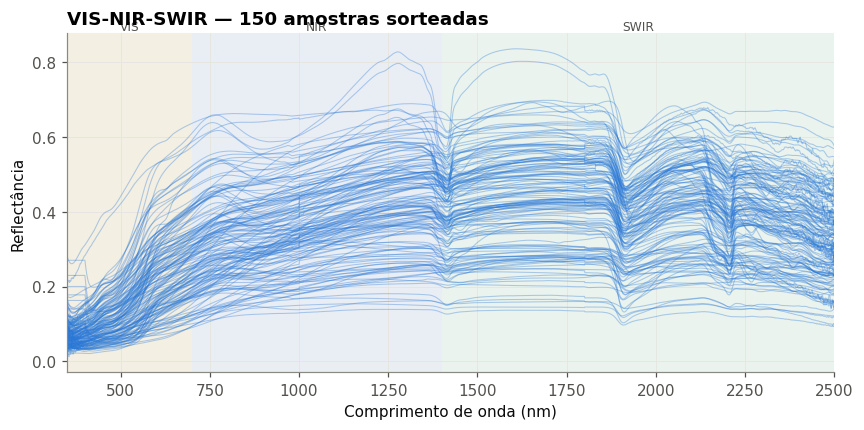

In [2]:
ax = vz.plot_spectra(ds.vnir, n_max=150, regions=True, title="VIS-NIR-SWIR — 150 amostras sorteadas")

## 2. Feições diagnósticas do VIS–NIR–SWIR
| Região | Atribuição principal |
|---|---|
| 480–530 nm, ~900 nm | óxidos de ferro (hematita, goethita) |
| ~1400 e ~1900 nm | água (OH e H–O–H) |
| ~2200 nm | Al–OH (caulinita, esmectita, ilita) |
| ~2265 nm | gibbsita |
| ~2330 nm | Mg/Fe–OH, carbonatos |

A matéria orgânica atua sobretudo no **albedo** (escurece todo o espectro).

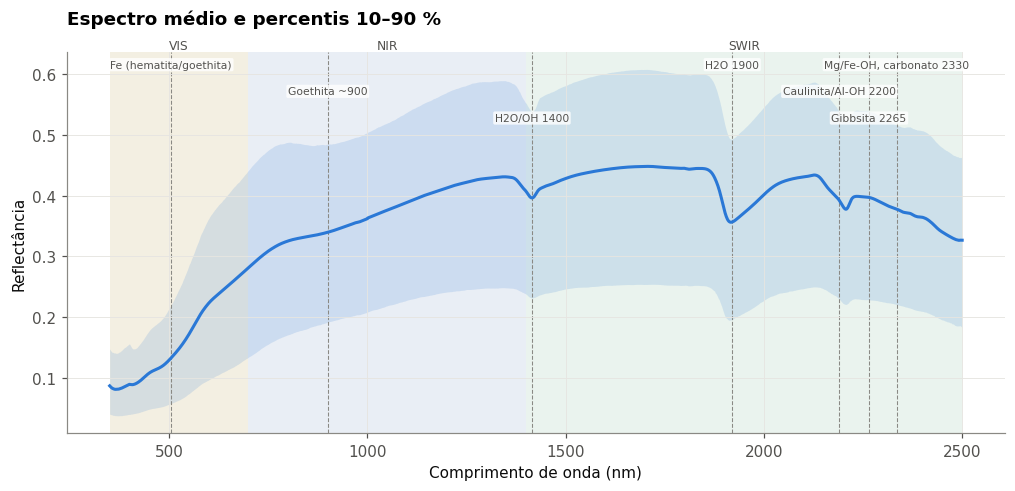

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
vz.plot_mean_std(ds.vnir, ax=ax, band="p10_90", regions=True)
vz.mark_features(ax)
ax.set_title("Espectro médio e percentis 10–90 %", loc="left", pad=18);

## 3. Colorindo por classe e por atributo

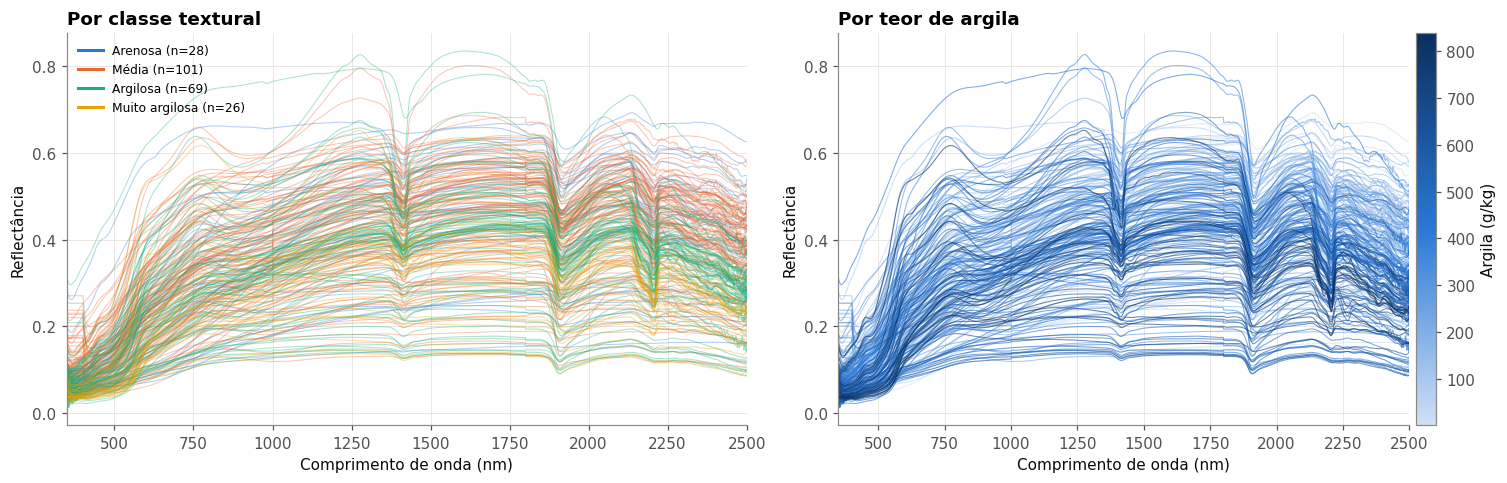

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
vz.plot_spectra(ds.vnir, color_by=ds.meta["Textura"], n_max=250, ax=axes[0], title="Por classe textural")
vz.plot_spectra(ds.vnir, color_by=ds.meta["Clay_gkg"], n_max=250, ax=axes[1],
                title="Por teor de argila", colorbar_label="Argila (g/kg)")
fig.tight_layout()

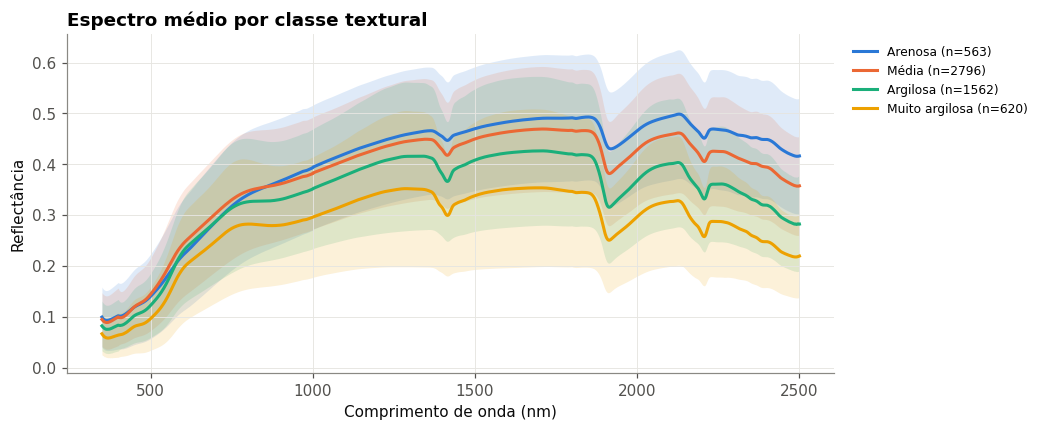

In [5]:
ax = vz.plot_mean_std(ds.vnir, groups=ds.meta["Textura"], title="Espectro médio por classe textural")

**Leitura:** solos mais argilosos tendem a ser mais escuros (mais óxidos de Fe e MO) e com feição
mais profunda em 2200 nm; solos arenosos têm albedo alto (quartzo). Na Aula 2 vamos **quantificar**
a feição de 2200 nm com a remoção do contínuo.

## 4. MIR
O eixo do MIR é **número de onda** (cm⁻¹), plotado de 4000 para 600 como nos espectrômetros.
Feições principais: OH da caulinita (3695/3620), C–H alifático da MO (2920/2850), quartzo
(sobretons 2000–1790), C=O/C=C (1600) e Si–O (~1000).

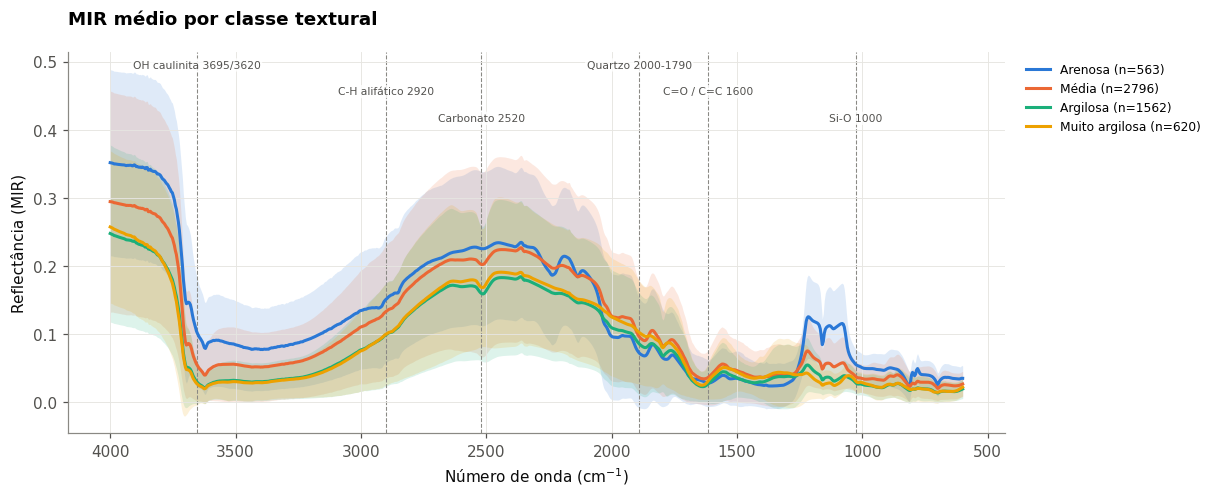

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
vz.plot_mean_std(ds.mir, groups=ds.meta["Textura"], ax=ax, ylabel="Reflectância (MIR)")
vz.mark_features(ax, mir=True)
ax.set_title("MIR médio por classe textural", loc="left", pad=18);

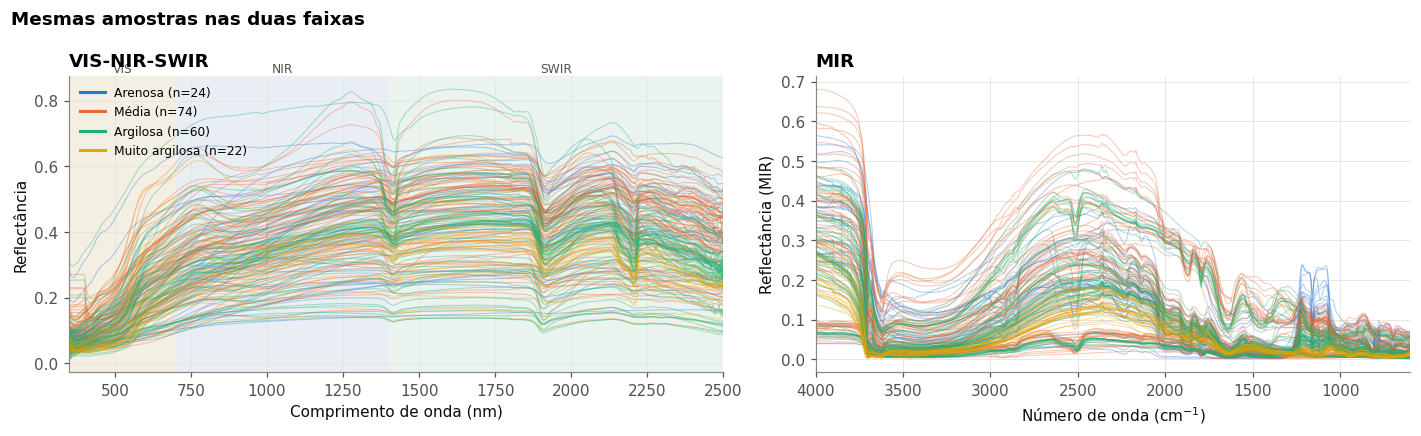

In [7]:
fig, axes = vz.plot_vnir_mir(ds, color_by=ds.meta["Textura"], n_max=200,
                             suptitle="Mesmas amostras nas duas faixas")

## 5. A base inteira de uma vez: heatmap
Cada linha é uma amostra; ordenando pela argila, o gradiente de albedo e as feições aparecem
como faixas. Linhas destoantes indicam possíveis problemas de leitura.

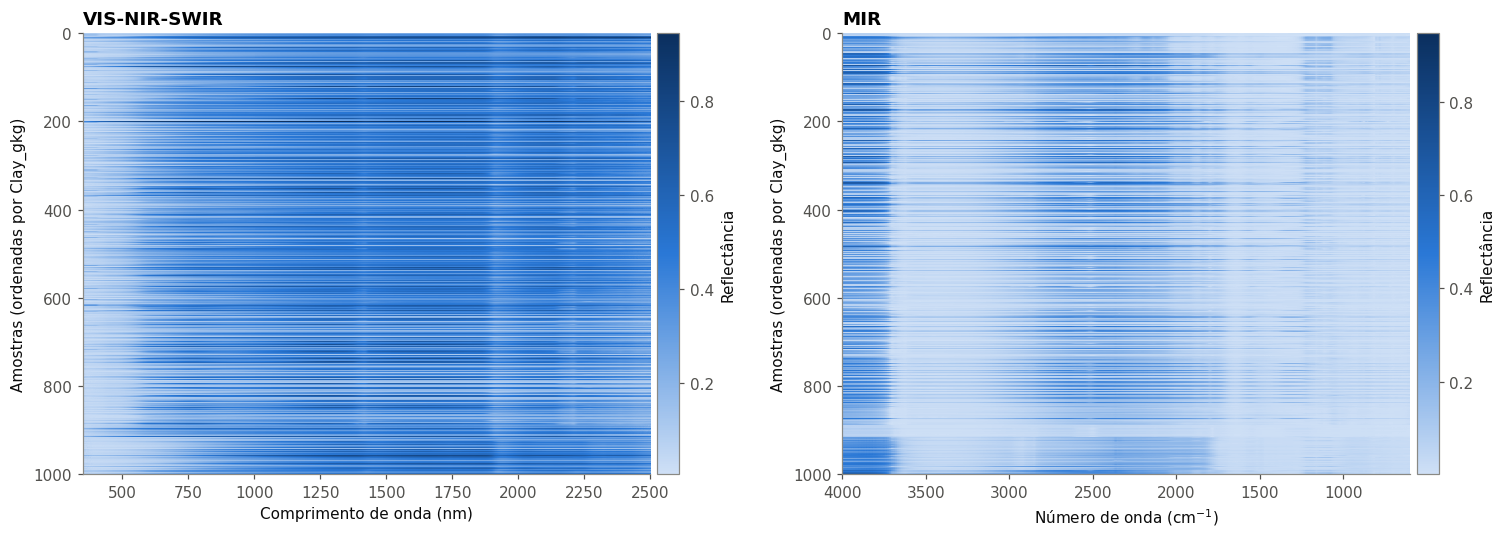

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
vz.plot_heatmap(ds.vnir, sort_by=ds.meta["Clay_gkg"], ax=axes[0], title="VIS-NIR-SWIR")
vz.plot_heatmap(ds.mir, sort_by=ds.meta["Clay_gkg"], ax=axes[1], title="MIR")
fig.tight_layout()

## 6. Salvando figuras (padrão do grupo: PNG 300 dpi em `outputs/figuras`)

WindowsPath('C:/Users/PC/Desktop/RESET/geocis-espectroscopia/outputs/figuras/aula01_vnir_medio_por_textura.png')

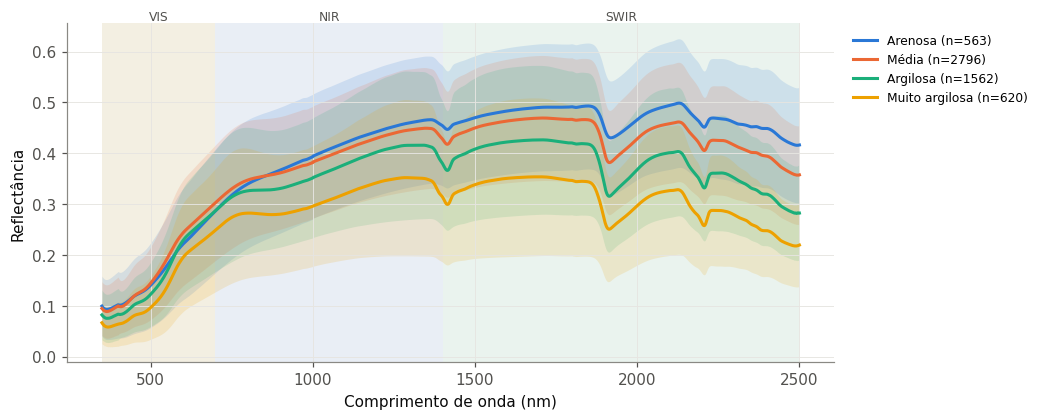

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
vz.plot_mean_std(ds.vnir, groups=ds.meta["Textura"], ax=ax, regions=True)
caminho = vz.savefig(fig, "aula01_vnir_medio_por_textura")
caminho

## Exercícios
1. Plote os espectros coloridos por **carbono** (`C_gkg`). O que acontece com o albedo?
2. Compare o espectro médio de dois `Owner` diferentes. As diferenças são de solo ou de equipamento?
3. Faça uma figura com 3 painéis: VIS (350–700), SWIR (2000–2500) e MIR (4000–3400) usando `pp.trim`.